In [1]:

# Test Google Drive connection
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


In [2]:

# Check that Chirchir can access Group G04 files
import os

BASE = "/content/drive/MyDrive/CSC4110_G04"

# Check the shared project folder
print("Group folder exists:", os.path.isdir(BASE))

# Check the dataset prepared by Collins Kipkorir
DATA_FILE = BASE + "/data/clean_credit.csv"

print("Dataset exists:", os.path.isfile(DATA_FILE))

# Display the actual shared folder path
print("Project location:", os.path.realpath(BASE))


Group folder exists: True
Dataset exists: True
Project location: /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 3.1 Linear regression and gradient descent |
| Owner (name) | Chirchir Collins |
| Registration number | COM/0020/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [3]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "3.1"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [4]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [5]:

# Task 3.1: Load the prepared Credit Risk Dataset

# Set the correct dataset path
DATA_FILE = "data/clean_credit.csv"

# Load the data prepared in Task 2.2
df = pd.read_csv(DATA_FILE)

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five loan records
display(df.head())

# Count originally observed interest rates
observed_rates = (df["rate_imputed"] == 0).sum()

print("Observed interest rates:", observed_rates)

# Confirm the regression target exists
print("Regression target:", "loan_int_rate")


Dataset shape: (32409, 25)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290


Observed interest rates: 29315
Regression target: loan_int_rate


## Task 3.1(a): Simple Linear Regression

In this section, I prepare the regression dataset, identify the numerical feature most strongly correlated with interest rate, and build a simple linear regression model.

In [6]:

# Task 3.1: Prepare regression training and testing data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use only loans with originally observed interest rates
regression_data = df[df["rate_imputed"] == 0].copy()

# Set the interest rate as our prediction target
y = regression_data["loan_int_rate"]

# Select numerical features and remove leakage columns
X = regression_data.select_dtypes(include="number").drop(
    columns=[
        "loan_int_rate",
        "loan_grade",
        "loan_status",
        "rate_imputed"
    ]
)

# Split into 80% training and 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Fit the scaler using training data only
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=X.columns,
    index=X_train_raw.index
)

# Transform testing data using the same scaler
X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns,
    index=X_test_raw.index
)

# Find the most strongly correlated training feature
train_correlations = X_train_raw.corrwith(y_train)

best_feature = train_correlations.abs().idxmax()

# Display our results
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nBest feature:", best_feature)
print("Correlation:", round(train_correlations[best_feature], 4))

print("\nData preparation completed successfully!")


Training records: 23452
Testing records: 5863
Number of features: 18

Best feature: cb_person_default_on_file
Correlation: 0.4995

Data preparation completed successfully!


In [7]:

# Task 3.1(a): Train a simple linear regression model

from sklearn.linear_model import LinearRegression

# Create the simple linear regression model
lr_simple = LinearRegression()

# Train using the best feature in its original units
lr_simple.fit(X_train_raw[[best_feature]], y_train)

# Obtain the intercept and slope
b0 = lr_simple.intercept_
b1 = lr_simple.coef_[0]

# Display the fitted equation
print("SIMPLE LINEAR REGRESSION RESULTS")
print("Best feature:", best_feature)
print("Intercept (b0):", round(b0, 4))
print("Slope (b1):", round(b1, 4))

print("\nFitted equation:")
print(f"Predicted interest rate = {b0:.4f} + ({b1:.4f} × x)")

# Predict rates for borrowers with and without a previous default
examples = pd.DataFrame({
    best_feature: [0, 1]
})

predictions = lr_simple.predict(examples)

print("\nPredictions:")
print("No previous default:", round(predictions[0], 4), "%")
print("Previous default:", round(predictions[1], 4), "%")


SIMPLE LINEAR REGRESSION RESULTS
Best feature: cb_person_default_on_file
Intercept (b0): 10.2722
Slope (b1): 4.2454

Fitted equation:
Predicted interest rate = 10.2722 + (4.2454 × x)

Predictions:
No previous default: 10.2722 %
Previous default: 14.5176 %


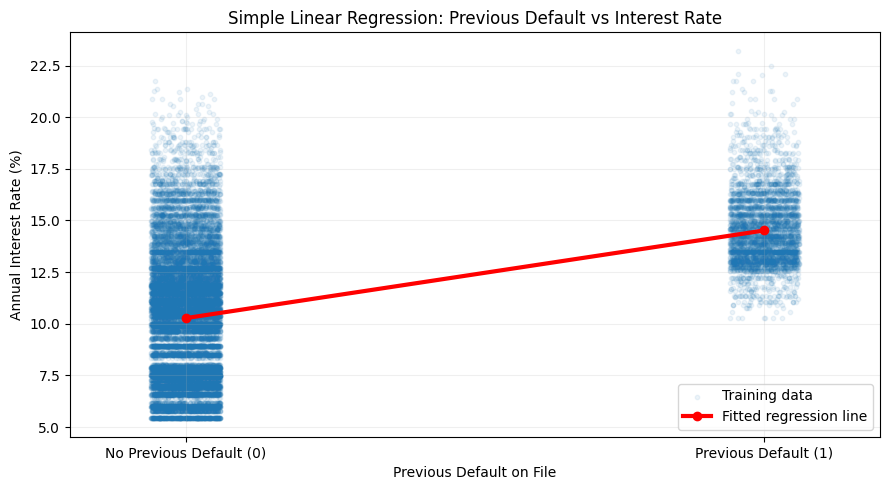

Saved: outputs/simple_fit.png


In [8]:

# Task 3.1(a): Plot simple linear regression

# Create small horizontal offsets to make points visible
rng = np.random.default_rng(42)
x_values = X_train_raw[best_feature].to_numpy()
x_jitter = x_values + rng.uniform(
    -0.06, 0.06, size=len(x_values)
)

# Create the graph
plt.figure(figsize=(9, 5))

# Plot the training data
plt.scatter(
    x_jitter,
    y_train,
    alpha=0.08,
    s=10,
    label="Training data"
)

# Calculate the fitted line at x = 0 and x = 1
line_x = pd.DataFrame({
    best_feature: [0, 1]
})

line_y = lr_simple.predict(line_x)

# Draw the regression line
plt.plot(
    [0, 1],
    line_y,
    color="red",
    linewidth=3,
    marker="o",
    label="Fitted regression line"
)

# Add the title and labels
plt.title("Simple Linear Regression: Previous Default vs Interest Rate")
plt.xlabel("Previous Default on File")
plt.ylabel("Annual Interest Rate (%)")

plt.xticks(
    [0, 1],
    ["No Previous Default (0)", "Previous Default (1)"]
)

plt.xlim(-0.2, 1.2)
plt.legend()
plt.grid(alpha=0.2)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/simple_fit.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/simple_fit.png")


In [9]:

# Task 3.1(a): Predict the first test row by hand

# Get the first test borrower's feature value
first_x = X_test_raw[best_feature].iloc[0]

# Get the actual interest rate
actual_rate = y_test.iloc[0]

# Calculate the prediction manually using y = b0 + b1*x
manual_prediction = b0 + b1 * first_x

# Confirm with the trained model
model_prediction = lr_simple.predict(
    X_test_raw[[best_feature]].iloc[[0]]
)[0]

# Calculate residual = actual - predicted
residual = actual_rate - manual_prediction

# Display the results
print("First test borrower:")
print("Previous default (x):", first_x)
print("Actual interest rate:", round(actual_rate, 4), "%")
print("Intercept (b0):", round(b0, 4))
print("Slope (b1):", round(b1, 4))

print("\nMANUAL CALCULATION")
print(f"Predicted = {b0:.4f} + ({b1:.4f} x {first_x})")
print("Manual prediction:", round(manual_prediction, 4), "%")

print("\nPYTHON CONFIRMATION")
print("Model prediction:", round(model_prediction, 4), "%")
print("Residual:", round(residual, 4))

# Confirm both predictions agree
assert np.isclose(manual_prediction, model_prediction)

print("\nSUCCESS: Manual and model predictions match!")


First test borrower:
Previous default (x): 0
Actual interest rate: 9.99 %
Intercept (b0): 10.2722
Slope (b1): 4.2454

MANUAL CALCULATION
Predicted = 10.2722 + (4.2454 x 0)
Manual prediction: 10.2722 %

PYTHON CONFIRMATION
Model prediction: 10.2722 %
Residual: -0.2822

SUCCESS: Manual and model predictions match!



### Task 3.1(a): Exam Skill — Interpreting Linear Regression

The fitted simple linear regression equation is:

Predicted interest rate = 10.2722 + 4.2454 × x

Where x represents whether a borrower has a previous default recorded (0 = No, 1 = Yes).

**Interpretation of the intercept (b0):**

The intercept is 10.2722. This means that the model predicts an annual interest rate of 10.2722% for a borrower without a previous default recorded.

**Interpretation of the slope (b1):**

The slope is 4.2454. This means that moving from no recorded previous default (0) to a recorded previous default (1) is associated with an increase of approximately 4.2454 percentage points in the predicted annual interest rate.

**Manual Prediction for the First Test Record:**

The first test borrower has x = 0.

Predicted = 10.2722 + (4.2454 × 0)

Predicted = 10.2722%

Actual interest rate = 9.9900%

Residual = Actual - Predicted

Residual = 9.9900 - 10.2722

Residual = -0.2822 percentage points.

The negative residual means that the predicted interest rate was slightly higher than the actual interest rate.

I confirmed this calculation using Python's predict() method, and both predictions matched.



## Task 3.1(b): Multiple Linear Regression

This section uses all 18 prepared numerical features to predict loan interest rates. The model is evaluated using MAE, MSE, RMSE and R² on both training and testing data.


In [10]:

# Task 3.1(b): Train and evaluate multiple linear regression

# Import the regression model and evaluation tools
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create the multiple linear regression model
lr_multi = LinearRegression()

# Train the model using all 18 prepared features
lr_multi.fit(X_train, y_train)

# Predict interest rates for training and testing data
train_predictions = lr_multi.predict(X_train)
test_predictions = lr_multi.predict(X_test)

# Calculate evaluation metrics
def calculate_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted)
    }

# Store the results in the required dictionary
metrics_multi = {
    "train": calculate_metrics(y_train, train_predictions),
    "test": calculate_metrics(y_test, test_predictions)
}

# Display the results in a table
print("MULTIPLE LINEAR REGRESSION RESULTS")

results_table = pd.DataFrame(metrics_multi).T

display(results_table.round(4))

# Display the number of features
print("Number of features:", X_train.shape[1])

print("\nMultiple regression completed successfully!")


MULTIPLE LINEAR REGRESSION RESULTS


,MAE,MSE,RMSE,R2
train,2.1990,7.4904,2.7369,0.2874
test,2.1889,7.3825,2.7171,0.2966


Number of features: 18

Multiple regression completed successfully!


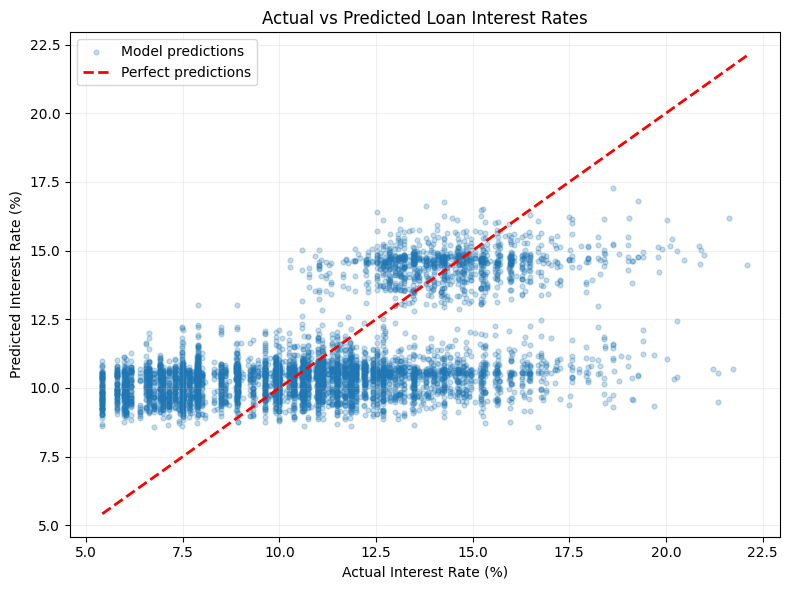

Saved: outputs/actual_vs_pred.png


In [11]:

# Task 3.1(b): Plot actual vs predicted interest rates

# Create the graph
plt.figure(figsize=(8, 6))

# Plot actual and predicted interest rates
plt.scatter(
    y_test,
    test_predictions,
    alpha=0.25,
    s=12,
    label="Model predictions"
)

# Calculate the range for the perfect prediction line
minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())

# Draw the perfect prediction line
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect predictions"
)

# Add title and labels
plt.title("Actual vs Predicted Loan Interest Rates")
plt.xlabel("Actual Interest Rate (%)")
plt.ylabel("Predicted Interest Rate (%)")

# Add legend and grid
plt.legend()
plt.grid(alpha=0.2)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/actual_vs_pred.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/actual_vs_pred.png")



## Task 3.1(c): Gradient Descent from Scratch

In this section, I implement gradient descent using NumPy to train a simple linear regression model.

I compare learning rates of 0.001, 0.01 and 0.1, observe how the cost decreases during training, and compare the final coefficients with scikit-learn.


Learning rate: 0.001
Final cost: 3.964906
Intercept: 10.821227
Slope: 1.589957
------------------------
Learning rate: 0.01
Final cost: 3.944170
Intercept: 11.022711
Slope: 1.619561
------------------------
Learning rate: 0.1
Final cost: 3.944170
Intercept: 11.022711
Slope: 1.619561
------------------------

GRADIENT DESCENT VS SCIKIT-LEARN
GD intercept: 11.022711
Sklearn intercept: 11.022711
GD slope: 1.619561
Sklearn slope: 1.619561


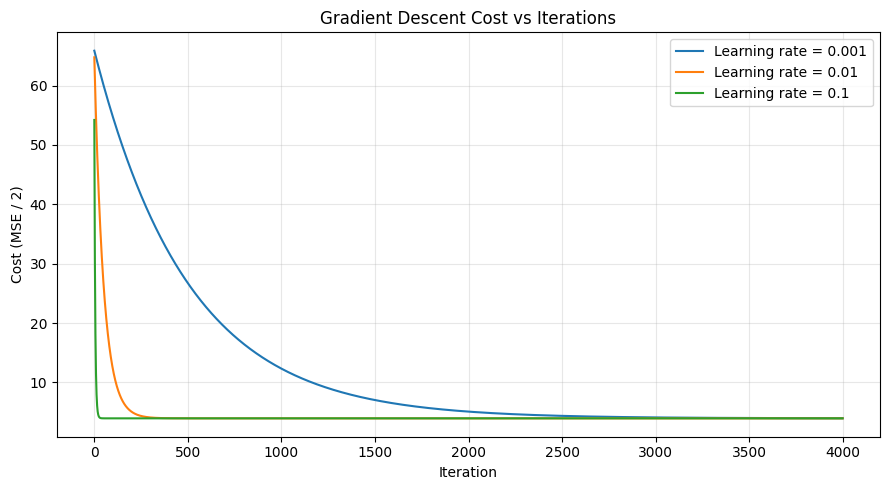


Saved: outputs/gd_cost.png


In [12]:

# Task 3.1(c): Implement gradient descent using NumPy

# Use the scaled version of our best feature
x_gd = X_train[best_feature].to_numpy()
y_gd = y_train.to_numpy()

# Learning rates required by the lecturer
learning_rates = [0.001, 0.01, 0.1]

# Number of training iterations
iterations = 4000

# Store the cost and coefficients for each learning rate
cost_history = {}
gd_results = {}

# Train separately using each learning rate
for learning_rate in learning_rates:

    # Start with zero intercept and slope
    b0_current = 0.0
    b1_current = 0.0

    costs = []

    # Repeat the learning process
    for i in range(iterations):

        # Calculate predicted interest rates
        predicted = b0_current + b1_current * x_gd

        # Calculate prediction errors
        errors = predicted - y_gd

        # Calculate gradients
        gradient_b0 = np.mean(errors)
        gradient_b1 = np.mean(errors * x_gd)

        # Update intercept and slope
        b0_current -= learning_rate * gradient_b0
        b1_current -= learning_rate * gradient_b1

        # Calculate cost after the update
        new_prediction = b0_current + b1_current * x_gd
        cost = np.mean((new_prediction - y_gd) ** 2) / 2

        costs.append(cost)

    # Save this learning rate's results
    cost_history[learning_rate] = costs
    gd_results[learning_rate] = (b0_current, b1_current)

    print(f"Learning rate: {learning_rate}")
    print(f"Final cost: {costs[-1]:.6f}")
    print(f"Intercept: {b0_current:.6f}")
    print(f"Slope: {b1_current:.6f}")
    print("------------------------")

# Use the converged 0.1 run for final coefficients
b0_gd, b1_gd = gd_results[0.1]

# Compare with scikit-learn on the SAME scaled feature
lr_scaled = LinearRegression()
lr_scaled.fit(X_train[[best_feature]], y_train)

print("\nGRADIENT DESCENT VS SCIKIT-LEARN")
print("GD intercept:", round(b0_gd, 6))
print("Sklearn intercept:", round(lr_scaled.intercept_, 6))
print("GD slope:", round(b1_gd, 6))
print("Sklearn slope:", round(lr_scaled.coef_[0], 6))

# Plot the cost history
plt.figure(figsize=(9, 5))

for learning_rate in learning_rates:
    plt.plot(
        cost_history[learning_rate],
        label=f"Learning rate = {learning_rate}"
    )

plt.title("Gradient Descent Cost vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Cost (MSE / 2)")
plt.legend()
plt.grid(alpha=0.3)

# Save and display the required graph
plt.tight_layout()
plt.savefig("outputs/gd_cost.png", dpi=150)
plt.show()

print("\nSaved: outputs/gd_cost.png")


In [13]:

# Task 3.1(c): Display final costs for the written answer

print("FINAL GRADIENT DESCENT COSTS")

for rate in [0.001, 0.01, 0.1]:
    final_cost = cost_history[rate][-1]
    print(f"Learning rate {rate}: {final_cost:.6f}")

print("\nFinal gradient descent coefficients:")
print(f"b0_gd = {b0_gd:.6f}")
print(f"b1_gd = {b1_gd:.6f}")


FINAL GRADIENT DESCENT COSTS
Learning rate 0.001: 3.964906
Learning rate 0.01: 3.944170
Learning rate 0.1: 3.944170

Final gradient descent coefficients:
b0_gd = 11.022711
b1_gd = 1.619561


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [14]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [15]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [16]:
# c1. <what this cell does>


## Written answer

### Task 3.1: Written Answer — Gradient Descent

With a learning rate of 0.001, the gradient descent cost decreased slowly and reached a final value of **3.964906** after 4,000 iterations.

With a learning rate of 0.01, the cost decreased faster and reached **3.944170**.

With a learning rate of 0.1, the cost decreased fastest and also reached **3.944170**, showing that the model converged more quickly.

The gradient descent intercept (**11.022711**) and slope (**1.619561**) matched scikit-learn to six decimal places because both methods minimise the same least-squares objective using the same scaled training feature.

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [17]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 3.1
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [18]:
# Paste the self-check cell from Moodle here
